<a href="https://colab.research.google.com/github/lin21022/Yuhsin-Lin/blob/main/holdout_starter_signs_v2_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Note: After you run this cell, the training and test data will be available in
# the file browser. (Click the folder icon on the left to view it)
#
# If you don't see the data after the cell completes, click the refresh button
# in the file browser (folder icon with circular arrow)

# First, let's download and unzip the data
!echo "Downloading files..."
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/training1.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/training2.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/holdout.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/mini_holdout.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/mini_holdout_answers.csv

!echo "Unzipping files..."
!unzip -q /content/training1.zip
!unzip -q /content/training2.zip
!unzip -q /content/holdout.zip
!unzip -q /content/mini_holdout.zip

# Combine the two traning directories
!echo "Merging training data..."
!mkdir /content/training
!mv /content/training1/* /content/training
!mv /content/training2/* /content/training

# Cleanup
!echo "Cleaning up..."
!rmdir /content/training1
!rmdir /content/training2
!rm training1.zip
!rm training2.zip
!rm holdout.zip
!rm mini_holdout.zip

!echo "Data ready."

Unzipping files...
Merging training data...
Cleaning up...
Data ready.


In [2]:
# Import libraries
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np

!pip install -q lets-plot
from lets_plot import *

LetsPlot.setup_html()


In [3]:
%load_ext tensorboard
import os
import datetime
run_name = datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
log_dir = os.path.join("/content/tensorboard_logs", run_name)

print("TensorBoard log directory:", log_dir)

TensorBoard log directory: /content/tensorboard_logs/20261116-202757


In [4]:
from sklearn.metrics import f1_score
import numpy as np

class MicroF1TensorBoard(tf.keras.callbacks.Callback):

    def __init__(self, validation_generator, log_dir):
        super().__init__()
        self.validation_generator = validation_generator
        self.writer = tf.summary.create_file_writer(log_dir)

    def on_epoch_end(self, epoch, logs=None):

        self.validation_generator.reset()

        true_labels = []
        predicted_labels = []

        for batch_index in range(len(self.validation_generator)):

            images, labels = self.validation_generator[batch_index]

            probabilities = self.model.predict(
                images,
                verbose=0
            )

            predictions = np.argmax(probabilities, axis=1)

            true_labels.extend(labels.astype(int))
            predicted_labels.extend(predictions)

        true_labels = np.array(
            true_labels[:self.validation_generator.samples]
        )

        predicted_labels = np.array(
            predicted_labels[:self.validation_generator.samples]
        )

        micro_f1 = f1_score(
            true_labels,
            predicted_labels,
            average="micro"
        )

        # Store the value in the Keras logs
        if logs is not None:
            logs["val_micro_f1"] = micro_f1

        # Write the value to TensorBoard
        with self.writer.as_default():
            tf.summary.scalar(
                "Validation Micro-F1",
                micro_f1,
                step=epoch
            )
            self.writer.flush()

        print(f" - val_micro_f1: {micro_f1:.4f}")

In [5]:
# We're using keras' ImageDataGenerator class to load our image data.
# See (https://keras.io/api/preprocessing/image/#imagedatagenerator-class) for details
#
# A couple of things to note:
# 1. We're specifying a number for the seed, so we'll always get the same shuffle and split of our images.
# 2. Class names are inferred automatically from the image subdirectory names.
# 3. We're splitting the training data into 80% training, 20% validation.


training_dir = '/content/training/'
image_size = (100, 100)

# Split up the training data images into training and validations sets
# We'll use and ImageDataGenerator to do the splits
# ImageDataGenerator can also be used to do preprocessing and agumentation on the files as can be seen with rescale

train_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=.2,
        # Geometric augmentation
        rotation_range=10,
        width_shift_range=0.08,
        height_shift_range=0.08,
        zoom_range=0.10,
        shear_range=0.05,

        # Lighting and color augmentation
        brightness_range=(0.7, 1.3),
        channel_shift_range=10,

        fill_mode="nearest"
        )
validation_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=.2
        )

train_generator = train_datagen.flow_from_directory(
        training_dir,
        target_size = image_size,
        subset="training",
        batch_size=32,
        class_mode='sparse',
        seed=42,shuffle=True)
validation_generator = validation_datagen.flow_from_directory(
    training_dir,
    target_size=(100, 100),
    batch_size=32,
    class_mode="sparse",
    subset="validation",
    seed=42,
    shuffle=False
)



Found 31368 images belonging to 43 classes.
Found 7841 images belonging to 43 classes.


In [6]:
import numpy as np

print("Number of classes:", train_generator.num_classes)
print("Class mapping:", train_generator.class_indices)

train_counts = np.bincount(train_generator.classes)
val_counts = np.bincount(validation_generator.classes)

print("Training samples:", train_generator.samples)
print("Validation samples:", validation_generator.samples)
print("Training class counts:", train_counts)
print("Validation class counts:", val_counts)

Number of classes: 43
Class mapping: {'00000': 0, '00001': 1, '00002': 2, '00003': 3, '00004': 4, '00005': 5, '00006': 6, '00007': 7, '00008': 8, '00009': 9, '00010': 10, '00011': 11, '00012': 12, '00013': 13, '00014': 14, '00015': 15, '00016': 16, '00017': 17, '00018': 18, '00019': 19, '00020': 20, '00021': 21, '00022': 22, '00023': 23, '00024': 24, '00025': 25, '00026': 26, '00027': 27, '00028': 28, '00029': 29, '00030': 30, '00031': 31, '00032': 32, '00033': 33, '00034': 34, '00035': 35, '00036': 36, '00037': 37, '00038': 38, '00039': 39, '00040': 40, '00041': 41, '00042': 42}
Training samples: 31368
Validation samples: 7841
Training class counts: [ 168 1776 1800 1128 1584 1488  336 1152 1128 1176 1608 1056 1680 1728
  624  504  336  888  960  168  288  264  312  408  216 1200  480  192
  432  216  360  624  192  552  336  960  312  168 1656  240  288  192
  192]
Validation class counts: [ 42 444 450 282 396 372  84 288 282 294 402 264 420 432 156 126  84 222
 240  42  72  66  78 10

In [7]:
#these might come in handy
target_names = ['Speed_20', 'Speed_30', 'Speed_50', 'Speed_60', 'Speed_70',
               'Speed_80','Speed_Limit_Ends', 'Speed_100', 'Speed_120', 'Overtaking_Prohibited',
               'Overtakeing_Prohibited_Trucks', 'Priority', 'Priority_Road_Ahead', 'Yield', 'STOP',
               'Entry_Forbidden', 'Trucks_Forbidden', 'No_Entry(one-way traffic)', 'General Danger(!)', 'Left_Curve_Ahead',
               'Right_Curve_Ahead', 'Double_Curve', 'Poor_Surface_Ahead', 'Slippery_Surface_Ahead', 'Road_Narrows_On_Right',
               'Roadwork_Ahead', 'Traffic_Light_Ahead', 'Warning_Pedestrians', 'Warning_Children', 'Warning_Bikes',
               'Ice_Snow', 'Deer_Crossing', 'End_Previous_Limitation', 'Turning_Right_Compulsory', 'Turning_Left_Compulsory',
               'Ahead_Only', 'Straight_Or_Right_Mandatory', 'Straight_Or_Left_Mandatory', 'Passing_Right_Compulsory', 'Passing_Left_Compulsory',
               'Roundabout', 'End_Overtaking_Prohibition', 'End_Overtaking_Prohibition_Trucks']

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sign_categories = {

    "Speed Limit": {
        "Speed_20", "Speed_30", "Speed_50", "Speed_60",
        "Speed_70", "Speed_80", "Speed_100", "Speed_120"
    },

    "Prohibition": {
        "Overtaking_Prohibited",
        "Overtakeing_Prohibited_Trucks",
        "Entry_Forbidden",
        "Trucks_Forbidden",
        "No_Entry(one-way traffic)"
    },

    "Priority and Right-of-Way": {
        "Priority",
        "Priority_Road_Ahead",
        "Yield",
        "STOP"
    },

    "Warning": {
        "General Danger(!)",
        "Left_Curve_Ahead",
        "Right_Curve_Ahead",
        "Double_Curve",
        "Poor_Surface_Ahead",
        "Slippery_Surface_Ahead",
        "Road_Narrows_On_Right",
        "Roadwork_Ahead",
        "Traffic_Light_Ahead",
        "Warning_Pedestrians",
        "Warning_Children",
        "Warning_Bikes",
        "Ice_Snow",
        "Deer_Crossing"
    },

    "Mandatory Direction": {
        "Turning_Right_Compulsory",
        "Turning_Left_Compulsory",
        "Ahead_Only",
        "Straight_Or_Right_Mandatory",
        "Straight_Or_Left_Mandatory",
        "Passing_Right_Compulsory",
        "Passing_Left_Compulsory",
        "Roundabout"
    },

    "End of Restriction": {
        "Speed_Limit_Ends",
        "End_Previous_Limitation",
        "End_Overtaking_Prohibition",
        "End_Overtaking_Prohibition_Trucks"
    }
}

In [ ]:
# View 9 images and their class labels
plt.figure(figsize=(10, 10))
images, labels = next(train_generator)  # Assuming train_generator is a generator
batch_size = images.shape[0]

for i in range(min(9, batch_size)):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow((images[i] * 255).astype("uint8"))
    plt.title(int(labels[i]))
    plt.axis("off")

plt.show()

In [9]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Build a model...
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, BatchNormalization,
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.models import load_model
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, 3, padding="same", activation="relu",
           input_shape=(100, 100, 3)),
    BatchNormalization(),
    MaxPooling2D(),

    Conv2D(64, 3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(),

    Conv2D(128, 3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(),

    Conv2D(256, 3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(),

    GlobalAveragePooling2D(),
    Dense(256, activation="relu"),
    Dropout(0.4),
    Dense(43, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.save(
    "/content/drive/MyDrive/traffic_sign_model_final.keras"
)




/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
checkpoint_path = (
    "/content/drive/MyDrive/traffic_sign_model_best.keras"
)

checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_accuracy',
    patience=4,          # Stop if no improvement for 4 epochs
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,          # Multiply learning rate by 0.2
    patience=2,          # Wait 2 epochs before reducing
    min_lr=1e-6
)

tensorboard_callback = tf.keras.callbacks.TensorBoard(
    log_dir=log_dir,
    histogram_freq=1,
    write_images=False,
    update_freq="epoch"
)

micro_f1_callback = MicroF1TensorBoard(
    validation_generator=validation_generator,
    log_dir=log_dir
)

callbacks_list = [
    tensorboard_callback,
    micro_f1_callback,
    checkpoint_callback,
    early_stopping,
    reduce_lr
]

history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=16,
    callbacks=callbacks_list
)

Epoch 1/16
981/981 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.2738 - loss: 2.7189 - val_micro_f1: 0.5997

Epoch 1: val_accuracy improved from None to 0.59967, saving model to /content/drive/MyDrive/traffic_sign_model_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/traffic_sign_model_best.keras
981/981 ━━━━━━━━━━━━━━━━━━━━ 170s 167ms/step - accuracy: 0.4254 - loss: 2.0667 - val_accuracy: 0.5997 - val_loss: 1.4139 - val_micro_f1: 0.5997 - learning_rate: 3.0000e-04
Epoch 2/16
981/981 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.8289 - loss: 0.6414 - val_micro_f1: 0.9093

Epoch 2: val_accuracy improved from 0.59967 to 0.90932, saving model to /content/drive/MyDrive/traffic_sign_model_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/traffic_sign_model_best.keras
981/981 ━━━━━━━━━━━━━━━━━━━━ 157s 160ms/step - accuracy: 0.8859 - loss: 0.4456 - val_accuracy: 0.9093 - val_loss: 0.3714 - val_micro_f1: 0.9093 - learning_rate: 3.0000e-04
Epoch 3/1

In [ ]:
import pandas as pd

log_dir = "/content/drive/MyDrive/traffic_sign_tensorboard"

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    "/content/drive/MyDrive/traffic_sign_training_history.csv",
    index=False
)

In [ ]:
from tensorflow.keras.models import load_model

model = load_model(
    "/content/drive/MyDrive/traffic_sign_model_best.keras"
)

In [ ]:
%tensorboard --logdir /content/tensorboard_logs

Reusing TensorBoard on port 6006 (pid 47241), started 2:09:17 ago. (Use '!kill 47241' to kill it.)

<IPython.core.display.Javascript object>

Mounted at /content/drive


In [ ]:
import os
import datetime

log_root = "/content/drive/MyDrive/traffic_sign_tensorboard"

run_name = "final_model_" + datetime.datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

log_dir = os.path.join(log_root, run_name)

print(log_dir)

/content/drive/MyDrive/traffic_sign_tensorboard/custom_final_model_20261115_025314


In [ ]:
%reload_ext tensorboard
%tensorboard --logdir /content/drive/MyDrive/traffic_sign_tensorboard

Reusing TensorBoard on port 6007 (pid 70245), started 0:50:02 ago. (Use '!kill 70245' to kill it.)

<IPython.core.display.Javascript object>

In [ ]:

# Convert Keras history to a DataFrame
history_df = pd.DataFrame(history.history)
history_df["epoch"] = range(1, len(history_df) + 1)

# Create a long-format DataFrame
plot_df = pd.DataFrame({
    "epoch": list(history_df["epoch"]) * 4,
    "value": (
        list(history_df["accuracy"]) +
        list(history_df["val_accuracy"]) +
        list(history_df["loss"]) +
        list(history_df["val_loss"])
    ),
    "metric": (
        ["Accuracy"] * len(history_df) +
        ["Accuracy"] * len(history_df) +
        ["Loss"] * len(history_df) +
        ["Loss"] * len(history_df)
    ),
    "dataset": (
        ["Training"] * len(history_df) +
        ["Validation"] * len(history_df) +
        ["Training"] * len(history_df) +
        ["Validation"] * len(history_df)
    )
})

# Plot using Lets-Plot
(
    ggplot(plot_df, aes(x="epoch", y="value", color="dataset"))
    + geom_line(size=1.2)
    + geom_point(size=2)
    + facet_grid(y="metric", scales="free_y")
    + labs(
        title="Training and Validation Performance",
        x="Epoch",
        y="Value",
        color="Dataset"
    )
    + theme_minimal()
    + ggsize(900, 600)
)

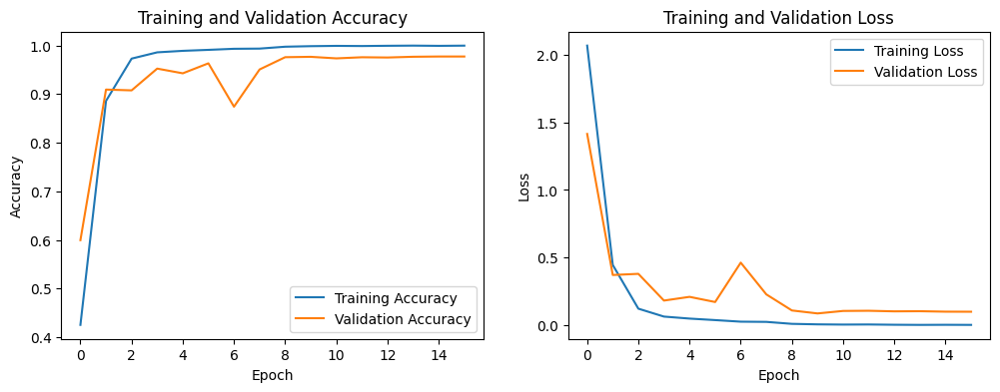

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')

plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

validation_generator.reset()

y_true = []
y_pred = []

for batch_index in range(len(validation_generator)):
    images, labels = validation_generator[batch_index]

    predictions = model.predict(images, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.astype(int))
    y_pred.extend(predicted_classes)

# Remove any extra samples
y_true = np.array(y_true[:validation_generator.samples])
y_pred = np.array(y_pred[:validation_generator.samples])

accuracy = accuracy_score(y_true, y_pred)
micro_f1 = f1_score(y_true, y_pred, average="micro")
macro_f1 = f1_score(y_true, y_pred, average="macro")

print(f"Accuracy: {accuracy:.4f}")
print(f"Micro-F1: {micro_f1:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")

Accuracy: 0.9773
Micro-F1: 0.9773
Macro-F1: 0.9552


Accuracy: 0.9833
Micro-F1: 0.9833
Macro-F1: 0.9699

Incorrect predictions: 155
Total validation images: 7841


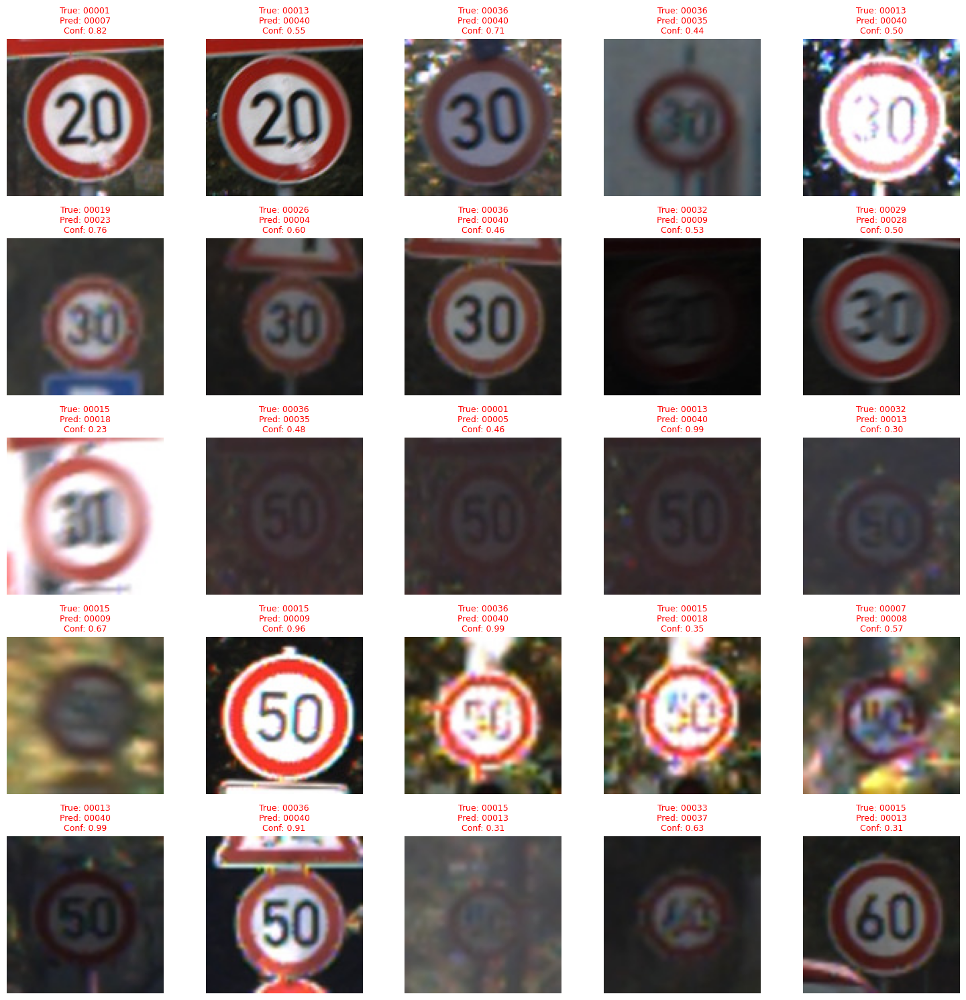

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

# Use the best saved model
best_model = load_model("/content/traffic_sign_model_checkpoint.keras")

validation_generator.reset()

y_true = []
y_pred = []
y_confidence = []

for batch_index in range(len(validation_generator)):
    images, labels = validation_generator[batch_index]

    probabilities = best_model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)

    y_true.extend(labels.astype(int))
    y_pred.extend(predictions)
    y_confidence.extend(confidence)

y_true = np.array(y_true[:validation_generator.samples])
y_pred = np.array(y_pred[:validation_generator.samples])
y_confidence = np.array(y_confidence[:validation_generator.samples])

# Find incorrect predictions
incorrect_indices = np.where(y_true != y_pred)[0]

print("Incorrect predictions:", len(incorrect_indices))
print("Total validation images:", validation_generator.samples)

# Convert class numbers back to folder names
class_names = {
    value: key for key, value in validation_generator.class_indices.items()
}

# Display up to 25 incorrect images
number_to_display = min(25, len(incorrect_indices))

plt.figure(figsize=(15, 15))

for plot_index, image_index in enumerate(
    incorrect_indices[:number_to_display]
):
    image_path = validation_generator.filepaths[image_index]
    image = load_img(image_path, target_size=(100, 100))

    true_label = class_names[y_true[image_index]]
    predicted_label = class_names[y_pred[image_index]]
    confidence = y_confidence[image_index]

    plt.subplot(5, 5, plot_index + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"True: {true_label}\n"
        f"Pred: {predicted_label}\n"
        f"Conf: {confidence:.2f}",
        fontsize=9,
        color="red"
    )

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
from lets_plot import *

report = classification_report(
    y_true,
    y_pred,
    output_dict=True,
    zero_division=0
)

class_performance = pd.DataFrame({
    "ClassId": range(43),
    "Sign": target_names,
    "F1": [report[str(i)]["f1-score"] for i in range(43)],
    "Recall": [report[str(i)]["recall"] for i in range(43)],
    "Precision": [report[str(i)]["precision"] for i in range(43)],
    "Samples": [report[str(i)]["support"] for i in range(43)]
})

class_performance = class_performance.sort_values("F1")

(
    ggplot(class_performance, aes(x="F1", y="Sign"))
    + geom_bar(stat="identity", fill="#4C78A8")
    + labs(
        title="F1 Score by Traffic-Sign Class",
        x="F1 Score",
        y="Traffic Sign"
    )
    + theme_minimal()
    + ggsize(900, 1000)
)

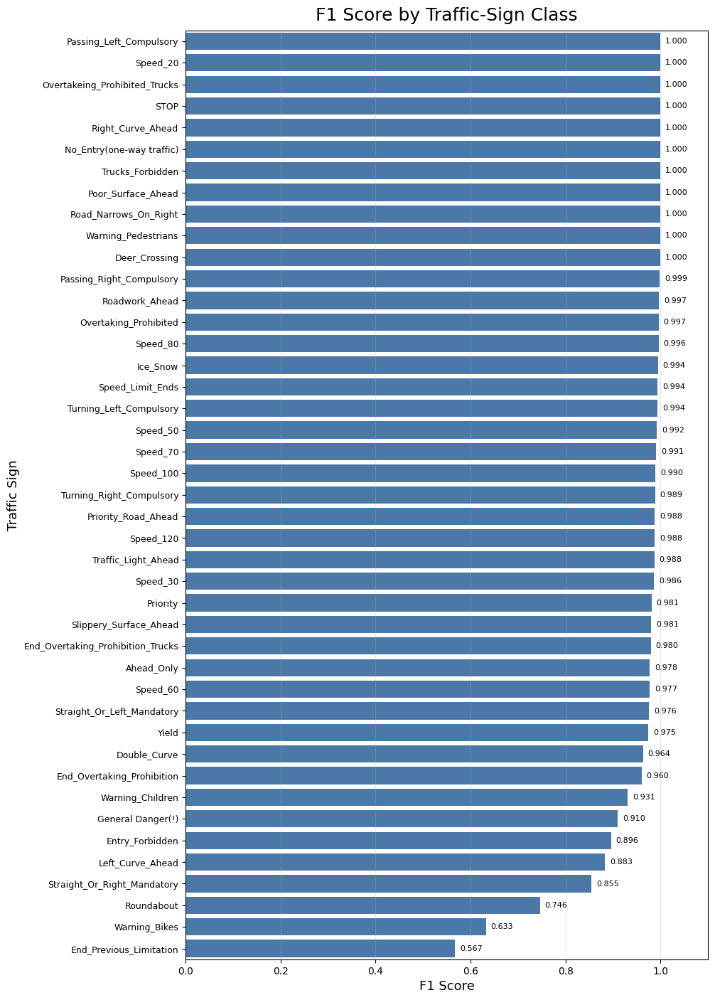

In [ ]:
fig, ax = plt.subplots(figsize=(10, 14))

bars = ax.barh(
    class_performance["Sign"],
    class_performance["F1"],
    color="#4C78A8"
)

ax.set_title(
    "F1 Score by Traffic-Sign Class",
    fontsize=18,
    pad=10
)

ax.set_xlabel("F1 Score", fontsize=13)
ax.set_ylabel("Traffic Sign", fontsize=13)

ax.set_xlim(0, 1.10)

# Remove extra space above and below the bars
ax.set_ylim(-0.5, len(class_performance) - 0.5)
ax.margins(y=0)

ax.tick_params(axis="y", labelsize=9)
ax.grid(axis="x", alpha=0.3)

for bar, score in zip(bars, class_performance["F1"]):
    ax.text(
        score + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.3f}",
        va="center",
        fontsize=8
    )

plt.tight_layout(pad=0.5)
plt.show()

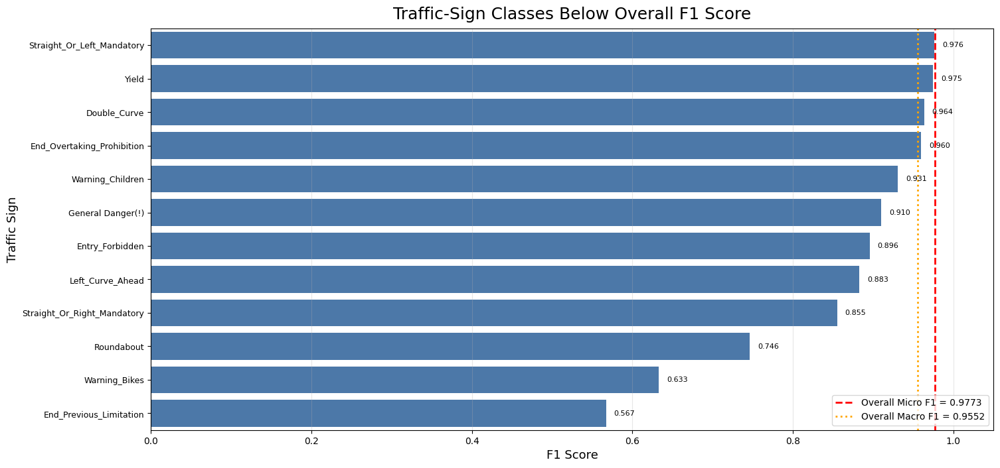

In [ ]:
f1_thres = max(micro_f1, macro_f1)

below_overall = class_performance[
    class_performance["F1"] < f1_thres
].sort_values("F1")
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(15, 7))

bars = ax.barh(
    below_overall["Sign"],
    below_overall["F1"],
    color="#4C78A8"
)

ax.axvline(
    micro_f1,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall Micro F1 = {micro_f1:.4f}"
)

ax.axvline(
    macro_f1,
    color="orange",
    linestyle=":",
    linewidth=2,
    label=f"Overall Macro F1 = {macro_f1:.4f}"
)

ax.set_title(
    "Traffic-Sign Classes Below Overall F1 Score",
    fontsize=18,
    pad=10
)

ax.set_xlabel("F1 Score", fontsize=13)
ax.set_ylabel("Traffic Sign", fontsize=13)

ax.set_xlim(0, 1.05)
ax.set_ylim(-0.5, len(below_overall) - 0.5)
ax.margins(y=0)

ax.tick_params(axis="y", labelsize=9)
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right")

# Add F1 values to the bars
for bar, score in zip(bars, below_overall["F1"]):
    ax.text(
        score + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.3f}",
        va="center",
        fontsize=8
    )

plt.tight_layout(pad=0.5)

fig.savefig(
    "/content/drive/MyDrive/traffic_sign_classes_below_overall_f1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [ ]:
class_performance

,ClassId,Sign,F1,Recall,Precision,Samples
32,32,End_Previous_Limitation,0.545455,0.375000,1.000000,48.0
29,29,Warning_Bikes,0.705882,0.555556,0.967742,54.0
15,15,Entry_Forbidden,0.882353,0.833333,0.937500,126.0
36,36,Straight_Or_Right_Mandatory,0.901408,0.820513,1.000000,78.0
40,40,Roundabout,0.925170,0.944444,0.906667,72.0
37,37,Straight_Or_Left_Mandatory,0.936709,0.880952,1.000000,42.0
1,1,Speed_30,0.946565,0.977477,0.917548,444.0
0,0,Speed_20,0.954545,1.000000,0.913043,42.0
21,21,Double_Curve,0.956522,1.000000,0.916667,66.0
19,19,Left_Curve_Ahead,0.962963,0.928571,1.000000,42.0


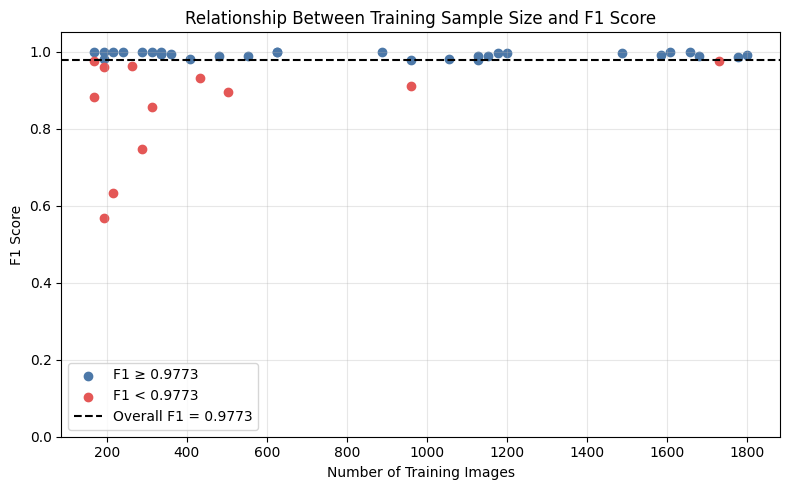

In [ ]:
plt.figure(figsize=(8, 5))

below_overall = class_performance["F1"] < 0.9773
class_performance["TrainingSamples"] = (
    class_performance["ClassId"]
    .map(dict(enumerate(train_counts)))
)
plt.scatter(
    class_performance.loc[~below_overall, "TrainingSamples"],
    class_performance.loc[~below_overall, "F1"],
    color="#4C78A8",
    label="F1 ≥ 0.9773"
)

plt.scatter(
    class_performance.loc[below_overall, "TrainingSamples"],
    class_performance.loc[below_overall, "F1"],
    color="#E45756",
    label="F1 < 0.9773"
)

plt.axhline(
    0.9773,
    color="black",
    linestyle="--",
    label="Overall F1 = 0.9773"
)

plt.xlabel("Number of Training Images")
plt.ylabel("F1 Score")
plt.title("Relationship Between Training Sample Size and F1 Score")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

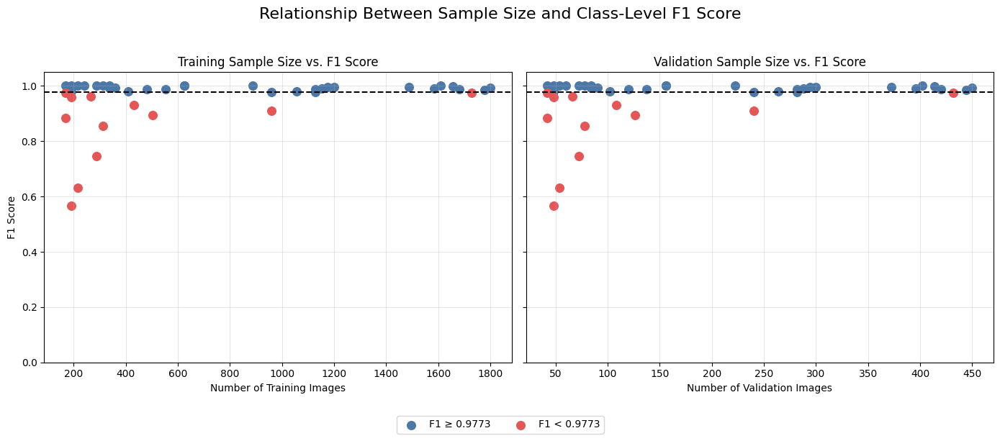

In [ ]:
import matplotlib.pyplot as plt

overall_f1 = 0.9773

# Ensure training counts match the correct ClassId
class_performance["TrainingSamples"] = (
    class_performance["ClassId"]
    .map(dict(enumerate(train_counts)))
)

above_overall = class_performance["F1"] >= overall_f1
below_overall = class_performance["F1"] < overall_f1

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    sharey=True
)

# -----------------------------
# Training sample size vs. F1
# -----------------------------
axes[0].scatter(
    class_performance.loc[above_overall, "TrainingSamples"],
    class_performance.loc[above_overall, "F1"],
    color="#4C78A8",
    s=70,
    label=f"F1 ≥ {overall_f1:.4f}"
)

axes[0].scatter(
    class_performance.loc[below_overall, "TrainingSamples"],
    class_performance.loc[below_overall, "F1"],
    color="#E45756",
    s=70,
    label=f"F1 < {overall_f1:.4f}"
)

axes[0].axhline(
    overall_f1,
    color="black",
    linestyle="--",
    linewidth=1.5
)

axes[0].set_title("Training Sample Size vs. F1 Score")
axes[0].set_xlabel("Number of Training Images")
axes[0].set_ylabel("F1 Score")
axes[0].set_ylim(0, 1.05)
axes[0].grid(True, alpha=0.3)

# -------------------------------
# Validation sample size vs. F1
# -------------------------------
axes[1].scatter(
    class_performance.loc[above_overall, "Samples"],
    class_performance.loc[above_overall, "F1"],
    color="#4C78A8",
    s=70
)

axes[1].scatter(
    class_performance.loc[below_overall, "Samples"],
    class_performance.loc[below_overall, "F1"],
    color="#E45756",
    s=70
)

axes[1].axhline(
    overall_f1,
    color="black",
    linestyle="--",
    linewidth=1.5
)

axes[1].set_title("Validation Sample Size vs. F1 Score")
axes[1].set_xlabel("Number of Validation Images")
axes[1].set_ylim(0, 1.05)
axes[1].grid(True, alpha=0.3)

# One shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.02)
)

fig.suptitle(
    "Relationship Between Sample Size and Class-Level F1 Score",
    fontsize=16
)

plt.tight_layout(rect=[0, 0.06, 1, 0.95])

fig.savefig(
    "/content/drive/MyDrive/traffic_sign_sample_size_vs_f1_side_by_side.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from scipy.stats import pearsonr, spearmanr
class_performance["TrainingSamples"] = (
    class_performance["ClassId"]
    .map(dict(enumerate(train_counts)))
)

training_corr, training_p = spearmanr(
    class_performance["TrainingSamples"],
    class_performance["F1"]
)

validation_corr, validation_p = spearmanr(
    class_performance["Samples"],
    class_performance["F1"]
)

print(f"Training samples vs. F1 correlation: {training_corr:.3f}")
print(f"Validation samples vs. F1 correlation: {validation_corr:.3f}")

Training samples vs. F1 correlation: 0.148
Validation samples vs. F1 correlation: 0.148


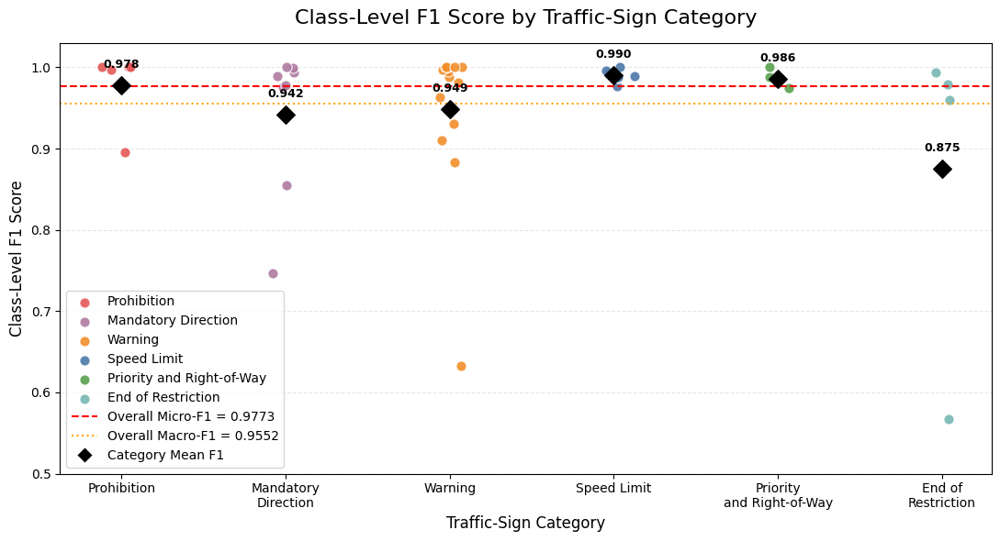

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

category_order = [
    "Prohibition",
    "Mandatory Direction",
    "Warning",
    "Speed Limit",
    "Priority and Right-of-Way",
    "End of Restriction"
]

category_colors = {
    "Warning": "#F28E2B",
    "Prohibition": "#E45756",
    "Speed Limit": "#4C78A8",
    "Priority and Right-of-Way": "#59A14F",
    "Mandatory Direction": "#B07AA1",
    "End of Restriction": "#76B7B2"
}

fig, ax = plt.subplots(figsize=(11, 6))

rng = np.random.default_rng(42)

for position, category in enumerate(category_order):

    values = class_performance.loc[
        class_performance["SignType"] == category,
        "F1"
    ].to_numpy()

    # Horizontal jitter prevents overlapping points
    jitter = rng.normal(0, 0.06, size=len(values))

    ax.scatter(
        position + jitter,
        values,
        s=65,
        color=category_colors[category],
        edgecolor="white",
        linewidth=0.8,
        alpha=0.9,
        label=category
    )

    category_mean = values.mean()

    # Category mean
    ax.scatter(
        position,
        category_mean,
        marker="D",
        s=100,
        color="black",
        zorder=4
    )

    ax.text(
        position,
        category_mean + 0.018,
        f"{category_mean:.3f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

ax.axhline(
    0.9773,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Overall Micro-F1 = 0.9773"
)

ax.axhline(
    0.9552,
    color="orange",
    linestyle=":",
    linewidth=1.5,
    label="Overall Macro-F1 = 0.9552"
)

ax.set_xticks(range(len(category_order)))
ax.set_xticklabels(category_order, rotation=20, ha="right")

ax.set_ylabel("Class-Level F1 Score", fontsize=12)
ax.set_xlabel("Traffic-Sign Category", fontsize=12)
ax.set_title(
    "Class-Level F1 Score by Traffic-Sign Category",
    fontsize=16,
    pad=15
)

# Focus on the region where most scores occur
ax.set_ylim(0.5, 1.03)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Show only the two reference-line labels
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[-2:],
    labels[-2:],
    loc="lower left",
    frameon=True
)
from matplotlib.lines import Line2D

# Wrap long category labels
pretty_labels = [
    "Prohibition",
    "Mandatory\nDirection",
    "Warning",

    "Speed Limit",
    "Priority\nand Right-of-Way",

    "End of\nRestriction"
]

ax.set_xticklabels(pretty_labels, rotation=0, ha="center")

# Add a legend entry for category means
mean_handle = Line2D(
    [0], [0],
    marker="D",
    color="white",
    markerfacecolor="black",
    markersize=9,
    label="Category Mean F1"
)

handles, labels = ax.get_legend_handles_labels()
handles.append(mean_handle)
labels.append("Category Mean F1")

ax.legend(
    handles,
    labels,
    loc="lower left",
    fontsize=10
)
plt.tight_layout()

fig.savefig(
    "/content/drive/MyDrive/traffic_sign_f1_by_category_clean.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Incorrect predictions: 155
Total validation images: 7841


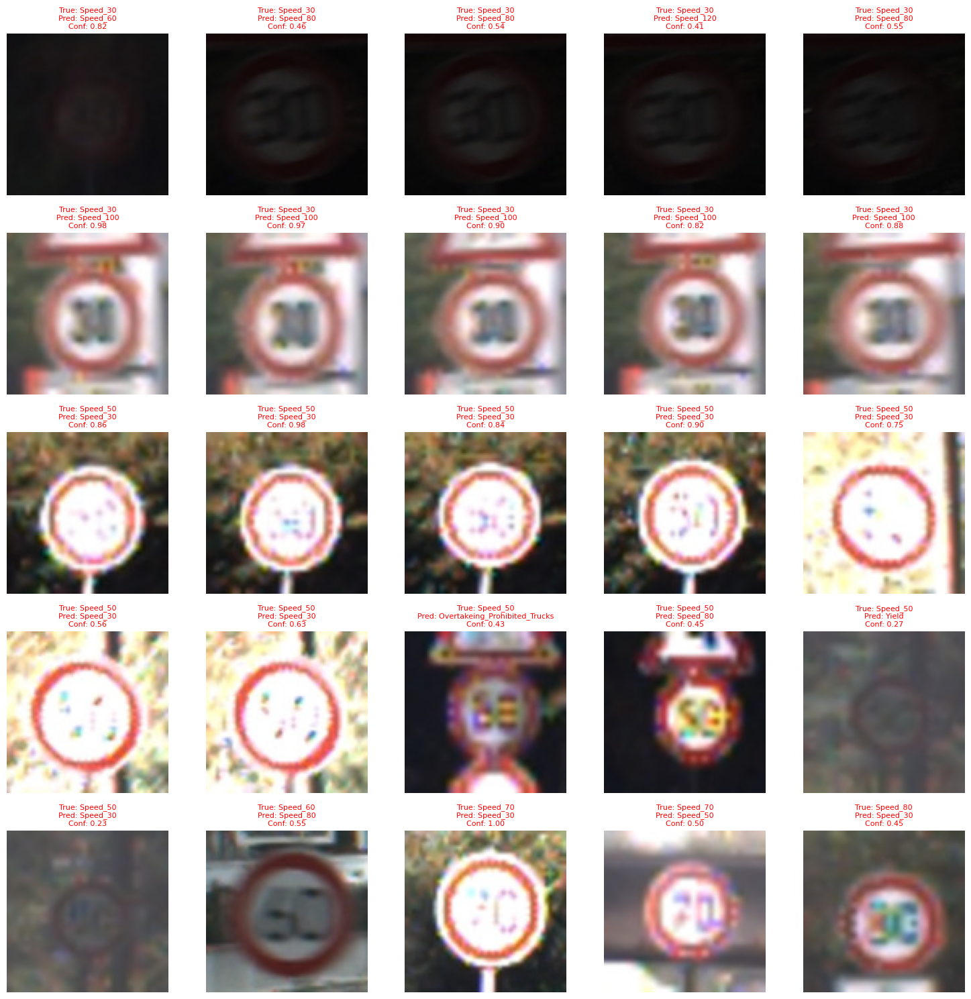

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import load_img

# Use the best saved model
best_model = load_model("/content/traffic_sign_model_checkpoint.keras")

validation_generator.reset()

y_true = []
y_pred = []
y_confidence = []

for batch_index in range(len(validation_generator)):
    images, labels = validation_generator[batch_index]

    probabilities = best_model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)

    y_true.extend(labels.astype(int))
    y_pred.extend(predictions)
    y_confidence.extend(confidence)

y_true = np.array(y_true[:validation_generator.samples])
y_pred = np.array(y_pred[:validation_generator.samples])
y_confidence = np.array(y_confidence[:validation_generator.samples])

# Find incorrect predictions
incorrect_indices = np.where(y_true != y_pred)[0]

print("Incorrect predictions:", len(incorrect_indices))
print("Total validation images:", validation_generator.samples)

# Map generator index -> folder name -> human-readable sign name
class_names = {
    value: target_names[int(key)]
    for key, value in validation_generator.class_indices.items()
}

# Display up to 25 incorrect images
number_to_display = min(25, len(incorrect_indices))

plt.figure(figsize=(15, 15))

for plot_index, image_index in enumerate(incorrect_indices[:number_to_display]):
    image_path = validation_generator.filepaths[image_index]
    image = load_img(image_path, target_size=(100, 100))

    true_label = class_names[y_true[image_index]]
    predicted_label = class_names[y_pred[image_index]]
    confidence = y_confidence[image_index]

    plt.subplot(5, 5, plot_index + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"True: {true_label}\n"
        f"Pred: {predicted_label}\n"
        f"Conf: {confidence:.2f}",
        fontsize=8,
        color="red"
    )

plt.tight_layout()
plt.show()

AttributeError: module 'matplotlib.pyplot' has no attribute 'xlab'

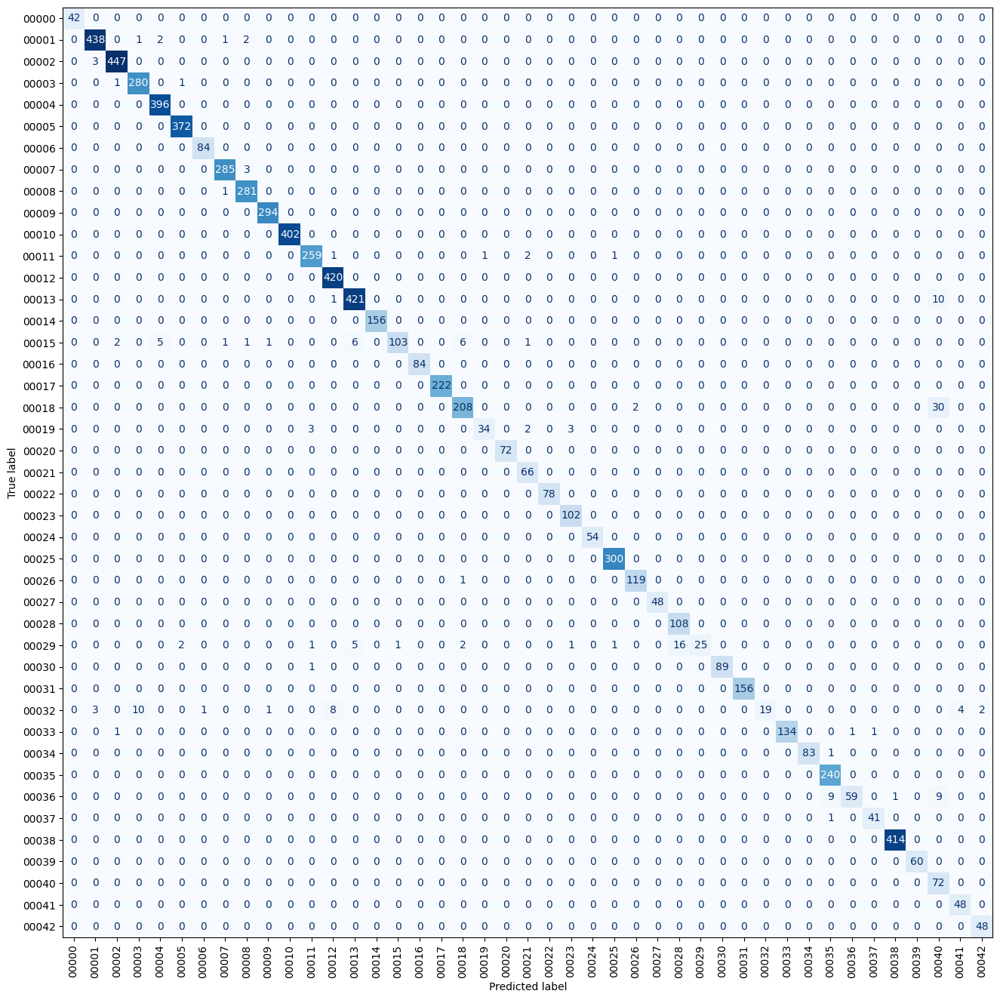

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(validation_generator.class_indices.keys())
)

fig, ax = plt.subplots(figsize=(16, 16))
disp.plot(ax=ax, xticks_rotation="vertical", cmap="Blues", colorbar=False)
plt.lab(size=14)
plt.title("Traffic Sign Confusion Matrix",size=18)
plt.show()

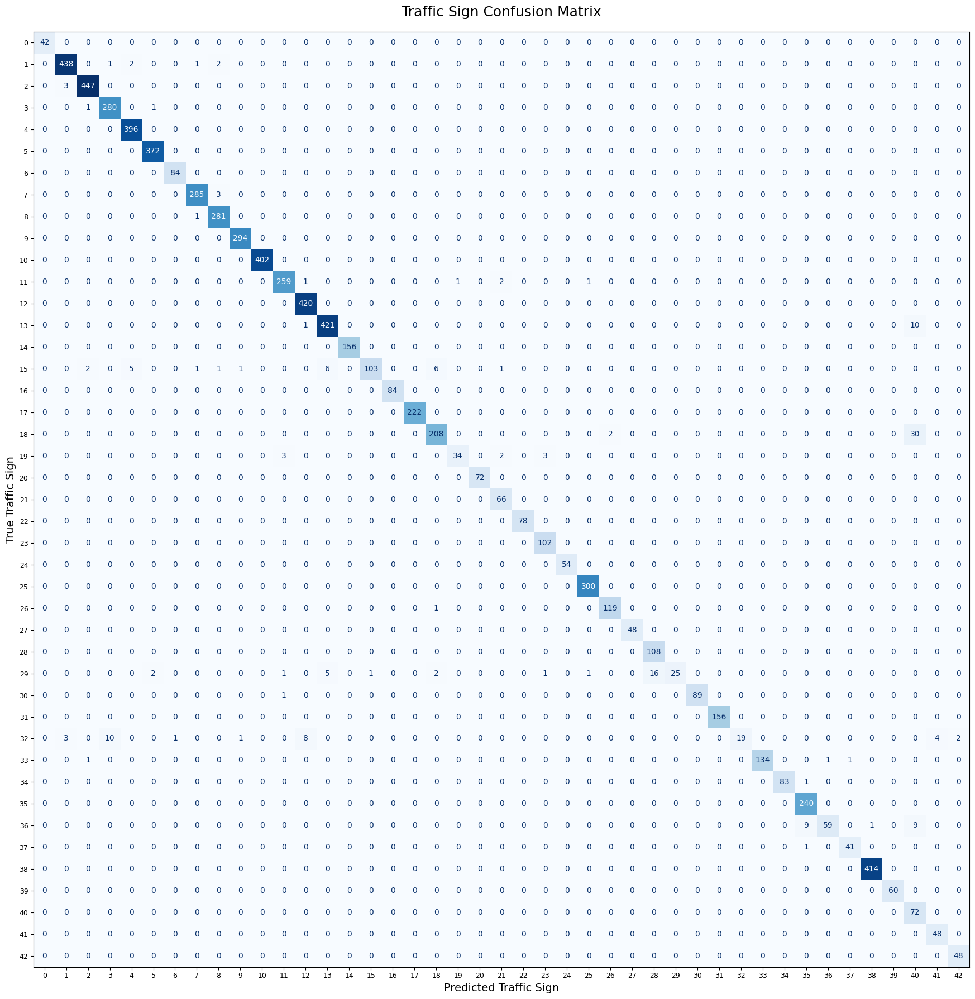

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

# Use human-readable traffic-sign names
display_labels = target_names
display_labels = list(range(43))

fig, ax = plt.subplots(figsize=(18, 18))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

ax.set_xlabel("Predicted Traffic Sign", fontsize=14)
ax.set_ylabel("True Traffic Sign", fontsize=14)
ax.set_title(
    "Traffic Sign Confusion Matrix",
    fontsize=18,
    pad=20
)

ax.tick_params(
    axis="both",
    labelsize=9
)

plt.tight_layout()


plt.savefig(
    "/content/drive/MyDrive/traffic_sign_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Testing the model
Once you have built and trained your model, the next step is to run the mini holdout images through it and see how well your model does at making predictions for images it has never seen before.

Since loading these images and formatting them for the model can be tricky, you may find the following code useful. This code only uses your model to predict the class label for a given image. You'll still need to compare those predictions to the "ground truth" class labels in `mini_holdout_answers.csv` to evaluate how well the model does.

Previously, you were given a file that would check your results. This time you're given the answers to the first mini holdout dataset. You'll need to compare those predictions against the "ground truth" class labels in `mini_holdout_answers.csv` to evaluate how well the model does.

Make sure to use the insights gained from the mini hold out dataset in your executive summary.


```
from tensorflow.keras.preprocessing import image_dataset_from_directory
test_dir = '/content/'

test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
        test_dir,
        classes=['mini_holdout'],
        target_size=image_size,
        class_mode='sparse',
        shuffle=False)
probabilities = model.predict(test_generator)
predictions = [np.argmax(probas) for probas in probabilities]
```



In [ ]:
import os
import glob
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, classification_report

In [ ]:
holdout_dir = "/content/mini_holdout"
answers_path = "/content/mini_holdout_answers.csv"

answers = pd.read_csv(answers_path)

print("Answer columns:")
print(answers.columns)
print(answers.head())

true_class_ids = answers["ClassId"].astype(int).to_numpy()
class_id_to_model_index = {
    int(folder_name): model_index
    for folder_name, model_index
    in validation_generator.class_indices.items()
}

true_labels = np.array([
    class_id_to_model_index[class_id]
    for class_id in true_class_ids
])

Answer columns:
Index(['Filename', 'ClassId'], dtype='object')
    Filename  ClassId
0  00000.jpg       16
1  00001.jpg        1
2  00002.jpg       38
3  00003.jpg       33
4  00004.jpg       11


In [ ]:
image_paths = sorted(
    glob.glob(os.path.join(holdout_dir, "*.jpg")) +
    glob.glob(os.path.join(holdout_dir, "*.jpeg")) +
    glob.glob(os.path.join(holdout_dir, "*.png"))
)

image_size = (100, 100)

images = []

for image_path in image_paths:
    image = Image.open(image_path).convert("RGB")
    image = image.resize(image_size)

    image_array = np.array(image, dtype=np.float32) / 255.0
    images.append(image_array)

images = np.array(images)

from tensorflow.keras.models import load_model

best_model = load_model(
    "/content/traffic_sign_model_checkpoint.keras"
)

predicted_probabilities = best_model.predict(images, verbose=1)
predicted_labels = np.argmax(predicted_probabilities, axis=1)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step


In [ ]:
accuracy = accuracy_score(true_labels, predicted_labels)

micro_f1 = f1_score(
    true_labels,
    predicted_labels,
    average="micro"
)

macro_f1 = f1_score(
    true_labels,
    predicted_labels,
    average="macro"
)

print(f"Accuracy: {accuracy:.4f}")
print(f"Micro-F1: {micro_f1:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")

Accuracy: 0.9900
Micro-F1: 0.9900
Macro-F1: 0.9918


In [ ]:
print(
    classification_report(
        true_labels,
        predicted_labels,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000        11
           2     1.0000    1.0000    1.0000         8
           3     1.0000    0.9000    0.9474        10
           4     1.0000    1.0000    1.0000         9
           5     0.7143    1.0000    0.8333         5
           6     1.0000    1.0000    1.0000         3
           7     1.0000    1.0000    1.0000         8
           8     1.0000    0.8333    0.9091         6
           9     1.0000    1.0000    1.0000        10
          10     1.0000    1.0000    1.0000        12
          11     1.0000    1.0000    1.0000         8
          12     1.0000    1.0000    1.0000         7
          13     1.0000    1.0000    1.0000        10
          14     1.0000    1.0000    1.0000         4
          15     1.0000    1.0000    1.0000         2
          16     1.0000    1.0000    1.0000         5
          17     1.0000    1.0000    1.0000         7
          18     1.0000    

##Mini Hold out Dataset


Once you feel confident, you will need to predict for the full holdout dataset using the following code, and submit your csv file:

```
from tensorflow.keras.preprocessing import image_dataset_from_directory
test_dir = '/content/'

test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
        test_dir,
        classes=['holdout'],
        target_size=image_size,
        class_mode='sparse',
        shuffle=False)
probabilities = model.predict(test_generator)
predictions = [np.argmax(probas) for probas in probabilities]
```

In [ ]:
import os
import numpy as np
import pandas as pd
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import load_model

# Load the best model
best_model = load_model(
    "/content/traffic_sign_model_checkpoint.keras"
)

image_size = (100, 100)
test_dir = "/content/"

test_datagen = ImageDataGenerator(
    rescale=1./255
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    classes=["holdout"],
    target_size=image_size,
    class_mode=None,
    shuffle=False
)

# Predict holdout images
probabilities = best_model.predict(test_generator, verbose=1)

predicted_model_indices = np.argmax(probabilities, axis=1)

Found 12630 images belonging to 1 classes.


395/395 ━━━━━━━━━━━━━━━━━━━━ 16s 38ms/step


In [ ]:
# Convert model output index back to original traffic-sign ClassId
index_to_class_id = {
    model_index: int(folder_name)
    for folder_name, model_index
    in train_generator.class_indices.items()
}

predicted_class_ids = np.array([
    index_to_class_id[index]
    for index in predicted_model_indices
])

filenames = [
    os.path.basename(path)
    for path in test_generator.filepaths
]

submission = pd.DataFrame({
    "ClassId": predicted_class_ids
})

submission_path = "/content/holdout_predictions.csv"
submission.to_csv(submission_path, index=False)

print(submission.head())
print("Number of predictions:", len(submission))
print("Saved to:", submission_path)

    Filename  ClassId
0  00000.jpg       16
1  00001.jpg        1
2  00002.jpg       38
3  00003.jpg       33
4  00004.jpg       11
Number of predictions: 12630
Saved to: /content/holdout_predictions.csv


In [ ]:
for class_id, sign_label in enumerate(target_names):
    print(f"{class_id}: {sign_label}")

0: Speed_20
1: Speed_30
2: Speed_50
3: Speed_60
4: Speed_70
5: Speed_80
6: Speed_Limit_Ends
7: Speed_100
8: Speed_120
9: Overtaking_Prohibited
10: Overtakeing_Prohibited_Trucks
11: Priority
12: Priority_Road_Ahead
13: Yield
14: STOP
15: Entry_Forbidden
16: Trucks_Forbidden
17: No_Entry(one-way traffic)
18: General Danger(!)
19: Left_Curve_Ahead
20: Right_Curve_Ahead
21: Double_Curve
22: Poor_Surface_Ahead
23: Slippery_Surface_Ahead
24: Road_Narrows_On_Right
25: Roadwork_Ahead
26: Traffic_Light_Ahead
27: Warning_Pedestrians
28: Warning_Children
29: Warning_Bikes
30: Ice_Snow
31: Deer_Crossing
32: End_Previous_Limitation
33: Turning_Right_Compulsory
34: Turning_Left_Compulsory
35: Ahead_Only
36: Straight_Or_Right_Mandatory
37: Straight_Or_Left_Mandatory
38: Passing_Right_Compulsory
39: Passing_Left_Compulsory
40: Roundabout
41: End_Overtaking_Prohibition
42: End_Overtaking_Prohibition_Trucks
